# 02 - (7,4) autoencoder over Rayleigh fading with receiver CSI
**Objective.** Repeat the (7,4) comparison when each 7-symbol block experiences one Rayleigh gain h (|h| Rayleigh, E|h|^2 = 1, i.e. block fading) and the receiver knows h.

**Receiver.** Zero-forcing equalisation x_hat = y/h (Task 1 `zf_equalize`, with the same magnitude floor). After ZF the noise std is sigma/|h|, so the AE decoder additionally receives the CSI |h|^2 as a ninth input; for Hamming-ML the per-block factor |h|^2 does not change the arg-min, so correlation on x_hat is still ML. Hard decision uses sign(x_hat). Uncoded BPSK uses the same fading realisations.

**Expected theory.** Uncoded BPSK with ZF/coherent detection: BER = 0.5 (1 - sqrt(g/(1+g))), g = Eb/N0 (slope 1/SNR, no diversity).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent.parent if Path.cwd().parent.name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from task2_autoencoder import experiments as ex, baselines as bl
from task2_autoencoder.autoencoder import load_model
pd.set_option("display.width", 160)
print("results ->", ex.RES, "| models ->", ex.MODELS)

results -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/results/exercise1_task2 | models -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/models/autoencoder


## 1. Train (random Eb/N0 in 0-20 dB per batch)

In [2]:
model, hist = ex.train_model("ae74_rayleigh")
print("config:", ex.CFG["ae74_rayleigh"])
h = pd.DataFrame(hist, columns=["step", "loss"]); display(h.iloc[[0, len(h)//2, -1]])

config: {'n_real': 7, 'rx_extra': 1, 'channel': 'rayleigh', 'rate': 0.5714285714285714, 'ebn0': (0.0, 20.0), 'steps': 8000, 'batch': 1024, 'lr': 0.003}


,step,loss
0,0,2.828978
20,4000,0.949734
40,7999,0.307186


## 2. Evaluate (2 million messages per point)

In [3]:
ae = load_model(ex.MODELS / "ae74_rayleigh.pt")
grid = np.arange(0, 25, 2.0)
dr = ex.eval_74(ae, "rayleigh", grid, 2_000_000)
dr.to_csv(ex.TAB / "ae74_rayleigh_results.csv", index=False)
display(dr.pivot(index="ebn0_db", columns="method", values="ber").round(6))
print("max |sim - theory| / theory for uncoded BPSK:", float((abs(dr[dr.method=='uncoded_bpsk'].ber.values / bl.bpsk_rayleigh(grid) - 1)).max()))

method,autoencoder,hamming_hard,hamming_ml,uncoded_bpsk
ebn0_db,,,,
0.0,0.191752,0.192560,0.167602,0.146308
2.0,0.141570,0.144520,0.122204,0.108528
4.0,0.100233,0.103520,0.085365,0.076948
6.0,0.068587,0.071268,0.057842,0.052910
8.0,0.045540,0.047771,0.038262,0.035294
10.0,0.030120,0.031458,0.024985,0.023307
12.0,0.019444,0.020385,0.016070,0.015084
14.0,0.012506,0.013027,0.010256,0.009668
16.0,0.007926,0.008255,0.006441,0.006160


max |sim - theory| / theory for uncoded BPSK: 0.01240149227416476


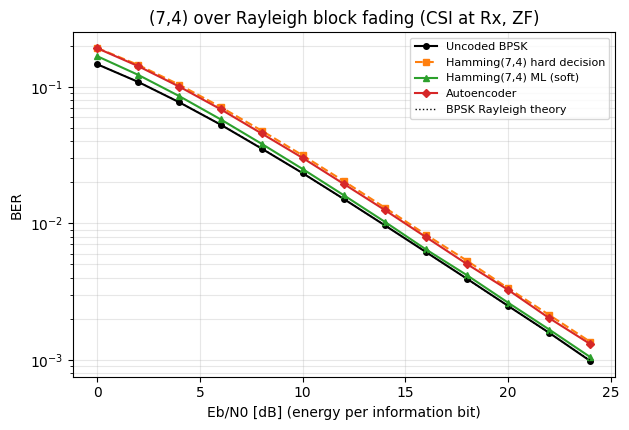

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
ex.plot_curves(dr, "ber", "(7,4) over Rayleigh block fading (CSI at Rx, ZF)", ax=ax)
ax.semilogy(grid, bl.bpsk_rayleigh(grid), "k:", lw=1, label="BPSK Rayleigh theory"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(ex.FIG / "ae74_rayleigh_ber.png", dpi=150); plt.show()

## 3. AWGN versus Rayleigh (AE and Hamming-ML)
The AWGN results come from notebook 01 (`ae74_awgn_results.csv`).

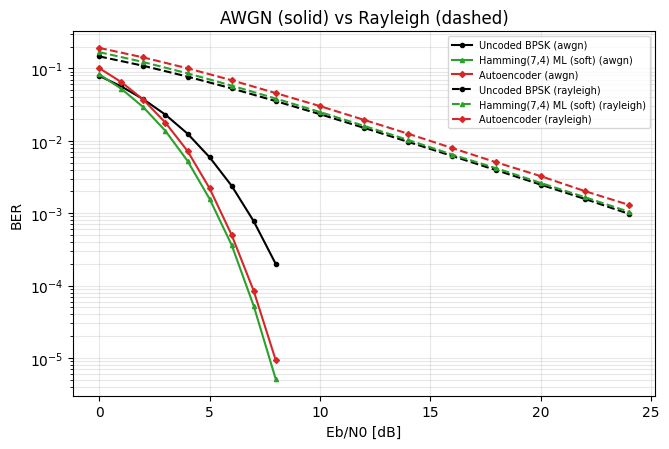

method,autoencoder,hamming_hard,hamming_ml,uncoded_bpsk
BER / BER(Hamming ML),,,,
0.0,1.14,1.15,1.0,0.87
2.0,1.16,1.18,1.0,0.89
4.0,1.17,1.21,1.0,0.90
6.0,1.19,1.23,1.0,0.91
8.0,1.19,1.25,1.0,0.92
10.0,1.21,1.26,1.0,0.93
12.0,1.21,1.27,1.0,0.94
14.0,1.22,1.27,1.0,0.94
16.0,1.23,1.28,1.0,0.96


In [5]:
da = pd.read_csv(ex.TAB / "ae74_awgn_results.csv")
both = pd.concat([da, dr])
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for ch, ls in (("awgn", "-"), ("rayleigh", "--")):
    for k in ("uncoded_bpsk", "hamming_ml", "autoencoder"):
        d = both[(both.channel == ch) & (both.method == k) & (both.ber > 0)]
        c, mk, _ = ex.STYLE[k]
        ax.semilogy(d.ebn0_db, d.ber, color=c, marker=mk, ls=ls, ms=3, label=f"{ex.LABELS[k]} ({ch})")
ax.set_xlabel("Eb/N0 [dB]"); ax.set_ylabel("BER"); ax.grid(True, which="both", alpha=.3); ax.legend(fontsize=7); ax.set_title("AWGN (solid) vs Rayleigh (dashed)")
fig.tight_layout(); fig.savefig(ex.FIG / "ae74_awgn_vs_rayleigh.png", dpi=150); plt.show()
p = dr.pivot(index="ebn0_db", columns="method", values="ber"); display((p.div(p.hamming_ml, axis=0)).round(2).rename_axis("BER / BER(Hamming ML)"))

* Fading destroys the exponential waterfall of AWGN: BER falls only like 1/SNR (about one decade per 10 dB) because a deep fade of the *single* gain hits all 7 symbols of the block together.
* Because one gain is shared by the whole codeword there is **no diversity** to exploit, and the code pays the 4/7 energy penalty. In this block-fading model uncoded BPSK is therefore *better* than every coded system: its BER is about 5-13 % lower than Hamming-ML (ratio 0.87-0.96 in the last table). A coding/diversity gain would require independent fades across the codeword (interleaving), which is outside the specified model.
* The AE with CSI follows the shape of Hamming-ML but stays 14-25 % above its BER at every point (ratio column; the gap grows slightly for Eb/N0 above its 0-20 dB training range), and is only slightly better than hard-decision Hamming. It does not beat ML.